In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
BASE_DIR = "/content/drive/MyDrive/Final yr/FracAtlas"

In [3]:
import os

print(os.listdir(BASE_DIR))

['dataset.csv', 'Annotations', 'Utilities', 'images']


In [4]:
import os

fractured_dir = os.path.join(BASE_DIR, "images", "Fractured")
nonfractured_dir = os.path.join(BASE_DIR, "images", "Non_fractured")

print("Fractured images:",
      len(os.listdir(fractured_dir)))

print("Non-fractured images:",
      len(os.listdir(nonfractured_dir)))

Fractured images: 719
Non-fractured images: 3366


In [5]:
import pandas as pd
import os

SPLIT_DIR = os.path.join(
    BASE_DIR,
    "Utilities",
    "Fracture Split"
)

train_csv = os.path.join(SPLIT_DIR, "train.csv")
valid_csv = os.path.join(SPLIT_DIR, "valid.csv")
test_csv = os.path.join(SPLIT_DIR, "test.csv")

train_df = pd.read_csv(train_csv)
valid_df = pd.read_csv(valid_csv)
test_df = pd.read_csv(test_csv)

print("Train CSV:")
print(train_df.head())

print("\nValidation CSV:")
print(valid_df.head())

print("\nTest CSV:")
print(test_df.head())

print("\nCounts:")
print("Train:", len(train_df))
print("Valid:", len(valid_df))
print("Test :", len(test_df))

Train CSV:
         image_id
0  IMG0000019.jpg
1  IMG0000025.jpg
2  IMG0000044.jpg
3  IMG0000057.jpg
4  IMG0000058.jpg

Validation CSV:
         image_id
0  IMG0003733.jpg
1  IMG0003734.jpg
2  IMG0003766.jpg
3  IMG0003767.jpg
4  IMG0003770.jpg

Test CSV:
         image_id
0  IMG0003297.jpg
1  IMG0003298.jpg
2  IMG0003301.jpg
3  IMG0003308.jpg
4  IMG0003309.jpg

Counts:
Train: 574
Valid: 82
Test : 63


In [6]:
import os
import pandas as pd

data = []

# Fractured
for filename in os.listdir(fractured_dir):
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):
        data.append({
            "image": os.path.join(fractured_dir, filename),
            "label": 1
        })

# Non-fractured
for filename in os.listdir(nonfractured_dir):
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):
        data.append({
            "image": os.path.join(nonfractured_dir, filename),
            "label": 0
        })

df = pd.DataFrame(data)

print("Total images:", len(df))
print(df["label"].value_counts())

Total images: 4085
label
0    3366
1     719
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Train:", len(train_df))
print("Valid:", len(valid_df))
print("Test :", len(test_df))

print("\nTrain labels:")
print(train_df["label"].value_counts())

print("\nValidation labels:")
print(valid_df["label"].value_counts())

print("\nTest labels:")
print(test_df["label"].value_counts())

Train: 2859
Valid: 613
Test : 613

Train labels:
label
0    2356
1     503
Name: count, dtype: int64

Validation labels:
label
0    505
1    108
Name: count, dtype: int64

Test labels:
label
0    505
1    108
Name: count, dtype: int64


In [8]:
!pip install -q timm

In [9]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import timm
import numpy as np

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [11]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [39]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True


# =========================
# TRAINING TRANSFORMS
# =========================

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.9, 1.1)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# =========================
# VALIDATION / TEST
# =========================

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# =========================
# DATASET
# =========================

class FracAtlasDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        image_path = self.dataframe.iloc[index]["image"]
        label = int(self.dataframe.iloc[index]["label"])

        try:

            image = Image.open(image_path).convert("RGB")

            if self.transform:
                image = self.transform(image)

            return image, torch.tensor(label, dtype=torch.long)

        except Exception as e:

            print("Problem with:", image_path)
            print("Error:", e)

            new_index = (index + 1) % len(self.dataframe)

            return self.__getitem__(new_index)

In [40]:
train_dataset = FracAtlasDataset(
    train_df,
    transform=train_transform
)

valid_dataset = FracAtlasDataset(
    valid_df,
    transform=test_transform
)

test_dataset = FracAtlasDataset(
    test_df,
    transform=test_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(valid_dataset))
print("Test:", len(test_dataset))

Train: 2859
Validation: 613
Test: 613


In [41]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

In [42]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [43]:
import timm

model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=True,
    num_classes=2
)

model = model.to(device)

print("ViT model loaded")

ViT model loaded


In [48]:
import numpy as np
import torch

train_labels = train_df["label"].values

class_counts = np.bincount(train_labels)

print("Class counts:")
print("Non-fractured:", class_counts[0])
print("Fractured:", class_counts[1])

total = len(train_labels)

weight_0 = total / (2 * class_counts[0])
weight_1 = total / (2 * class_counts[1])

class_weights = torch.tensor(
    [weight_0, weight_1],
    dtype=torch.float
).to(device)

print("Class weights:", class_weights)

Class counts:
Non-fractured: 2356
Fractured: 503
Class weights: tensor([0.6067, 2.8419], device='cuda:0')


In [49]:
criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

In [50]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=5e-5,
    weight_decay=1e-4
)

In [53]:
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10
)

In [54]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import copy

num_epochs = 10

best_f1 = 0.0
best_model = copy.deepcopy(model)

for epoch in range(num_epochs):

    # =========================
    # TRAIN
    # =========================

    model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_accuracy = train_correct / train_total

    # =========================
    # VALIDATION
    # =========================

    model.eval()

    val_preds = []
    val_labels = []

    with torch.no_grad():

        for images, labels in valid_loader:

            images = images.to(device)

            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            val_preds.extend(
                predictions.cpu().numpy()
            )

            val_labels.extend(
                labels.numpy()
            )

    val_accuracy = accuracy_score(
        val_labels,
        val_preds
    )

    val_precision = precision_score(
        val_labels,
        val_preds,
        zero_division=0
    )

    val_recall = recall_score(
        val_labels,
        val_preds,
        zero_division=0
    )

    val_f1 = f1_score(
        val_labels,
        val_preds,
        zero_division=0
    )

    scheduler.step()

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Acc: {val_accuracy:.4f} "
        f"Precision: {val_precision:.4f} "
        f"Recall: {val_recall:.4f} "
        f"F1: {val_f1:.4f}"
    )

    # Save best model according to F1
    if val_f1 > best_f1:

        best_f1 = val_f1

        best_model = copy.deepcopy(model)

        torch.save(
            model.state_dict(),
            "/content/drive/MyDrive/Final yr/best_vit_fracture.pth"
        )

        print("Best model saved!")

Epoch [1/10] Train Acc: 0.7394 Val Acc: 0.7879 Precision: 0.4433 Recall: 0.7963 F1: 0.5695
Best model saved!
Epoch [2/10] Train Acc: 0.7845 Val Acc: 0.8091 Precision: 0.4724 Recall: 0.7130 F1: 0.5683
Epoch [3/10] Train Acc: 0.8195 Val Acc: 0.8679 Precision: 0.6286 Recall: 0.6111 F1: 0.6197
Best model saved!
Epoch [4/10] Train Acc: 0.8405 Val Acc: 0.8369 Precision: 0.5256 Recall: 0.7593 F1: 0.6212
Best model saved!
Epoch [5/10] Train Acc: 0.8713 Val Acc: 0.8972 Precision: 0.7419 Recall: 0.6389 F1: 0.6866
Best model saved!
Epoch [6/10] Train Acc: 0.8916 Val Acc: 0.8548 Precision: 0.5674 Recall: 0.7407 F1: 0.6426
Epoch [7/10] Train Acc: 0.9112 Val Acc: 0.8679 Precision: 0.6134 Recall: 0.6759 F1: 0.6432
Epoch [8/10] Train Acc: 0.9332 Val Acc: 0.8777 Precision: 0.6341 Recall: 0.7222 F1: 0.6753
Epoch [9/10] Train Acc: 0.9405 Val Acc: 0.8956 Precision: 0.7037 Recall: 0.7037 F1: 0.7037
Best model saved!
Epoch [10/10] Train Acc: 0.9556 Val Acc: 0.8923 Precision: 0.6981 Recall: 0.6852 F1: 0.6916

In [55]:
model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Final yr/best_vit_fracture.pth",
        map_location=device
    )
)

model = model.to(device)

print("Best model loaded")

Best model loaded


In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

model.eval()

all_labels = []
all_preds = []
all_probs = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(
            outputs, dim=1
        )

        predictions = torch.argmax(
            probabilities, dim=1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_preds.extend(
            predictions.cpu().numpy()
        )

        all_probs.extend(
            probabilities[:, 1].cpu().numpy()
        )


accuracy = accuracy_score(
    all_labels,
    all_preds
)

precision = precision_score(
    all_labels,
    all_preds,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_preds,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_preds,
    zero_division=0
)

roc_auc = roc_auc_score(
    all_labels,
    all_probs
)

cm = confusion_matrix(
    all_labels,
    all_preds
)

print("\n========== FINAL RESULTS ==========")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", roc_auc)

print("\nConfusion Matrix:")
print(cm)


========== FINAL RESULTS ==========
Accuracy : 0.8890701468189234
Precision: 0.6818181818181818
Recall   : 0.6944444444444444
F1 Score : 0.6880733944954128
ROC-AUC  : 0.8827649431609828

Confusion Matrix:
[[470  35]
 [ 33  75]]


In [58]:
import shutil

shutil.copy(
    "/content/drive/MyDrive/Final yr/best_vit_fracture.pth",
    "/content/drive/MyDrive/Final yr/best_vit_fracture_exp1.pth"
)

print("Baseline model saved!")

Baseline model saved!


In [ ]:
EXPERIMENT 2

In [59]:
import timm
import torch

model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=True,
    num_classes=2
)

model = model.to(device)

print("ViT-B/16 loaded successfully")

ViT-B/16 loaded successfully


In [60]:
class_weights = torch.tensor(
    [0.6067, 2.8419],
    dtype=torch.float
).to(device)

print("Class weights:", class_weights)

Class weights: tensor([0.6067, 2.8419], device='cuda:0')


In [61]:
criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

In [62]:
optimizer = torch.optim.AdamW(
    [
        {
            "params": model.blocks.parameters(),
            "lr": 2e-5
        },
        {
            "params": model.patch_embed.parameters(),
            "lr": 2e-5
        },
        {
            "params": model.norm.parameters(),
            "lr": 2e-5
        },
        {
            "params": model.head.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

print("Optimizer created")

Optimizer created


In [63]:
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=12,
    eta_min=1e-6
)

In [64]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import copy
import torch

num_epochs = 12

best_f1 = 0.0

best_model = copy.deepcopy(model)

for epoch in range(num_epochs):

    # =========================
    # TRAINING
    # =========================

    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        # Prevent very large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)

        train_correct += (
            predicted == labels
        ).sum().item()

    train_accuracy = (
        train_correct / train_total
    )

    # =========================
    # VALIDATION
    # =========================

    model.eval()

    val_preds = []
    val_labels = []

    with torch.no_grad():

        for images, labels in valid_loader:

            images = images.to(device)

            outputs = model(images)

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            val_preds.extend(
                predictions.cpu().numpy()
            )

            val_labels.extend(
                labels.numpy()
            )

    # =========================
    # METRICS
    # =========================

    val_accuracy = accuracy_score(
        val_labels,
        val_preds
    )

    val_precision = precision_score(
        val_labels,
        val_preds,
        zero_division=0
    )

    val_recall = recall_score(
        val_labels,
        val_preds,
        zero_division=0
    )

    val_f1 = f1_score(
        val_labels,
        val_preds,
        zero_division=0
    )

    # =========================
    # LR UPDATE
    # =========================

    scheduler.step()

    # =========================
    # PRINT
    # =========================

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Acc: {val_accuracy:.4f} "
        f"Precision: {val_precision:.4f} "
        f"Recall: {val_recall:.4f} "
        f"F1: {val_f1:.4f}"
    )

    # =========================
    # SAVE BEST MODEL
    # =========================

    if val_f1 > best_f1:

        best_f1 = val_f1

        best_model = copy.deepcopy(model)

        torch.save(
            model.state_dict(),
            "/content/drive/MyDrive/Final yr/best_vit_fracture_exp2.pth"
        )

        print(
            f"Best model saved! "
            f"F1 = {best_f1:.4f}"
        )

Epoch [1/12] Train Acc: 0.6859 Val Acc: 0.8303 Precision: 0.5147 Recall: 0.6481 F1: 0.5738
Best model saved! F1 = 0.5738
Epoch [2/12] Train Acc: 0.7884 Val Acc: 0.8385 Precision: 0.5306 Recall: 0.7222 F1: 0.6118
Best model saved! F1 = 0.6118
Epoch [3/12] Train Acc: 0.8451 Val Acc: 0.8923 Precision: 0.8000 Recall: 0.5185 F1: 0.6292
Best model saved! F1 = 0.6292
Epoch [4/12] Train Acc: 0.8804 Val Acc: 0.8809 Precision: 0.6522 Recall: 0.6944 F1: 0.6726
Best model saved! F1 = 0.6726
Epoch [5/12] Train Acc: 0.9007 Val Acc: 0.8303 Precision: 0.5122 Recall: 0.7778 F1: 0.6176
Epoch [6/12] Train Acc: 0.9272 Val Acc: 0.9038 Precision: 0.8025 Recall: 0.6019 F1: 0.6878
Best model saved! F1 = 0.6878
Epoch [7/12] Train Acc: 0.9321 Val Acc: 0.9038 Precision: 0.7634 Recall: 0.6574 F1: 0.7065
Best model saved! F1 = 0.7065
Epoch [8/12] Train Acc: 0.9493 Val Acc: 0.9119 Precision: 0.7812 Recall: 0.6944 F1: 0.7353
Best model saved! F1 = 0.7353
Epoch [9/12] Train Acc: 0.9573 Val Acc: 0.9070 Precision: 0.74

In [65]:
model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Final yr/best_vit_fracture_exp2.pth",
        map_location=device
    )
)

model = model.to(device)

print("Best Experiment 2 model loaded")

Best Experiment 2 model loaded


In [66]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

model.eval()

all_labels = []
all_preds = []
all_probs = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_preds.extend(
            predictions.cpu().numpy()
        )

        all_probs.extend(
            probabilities[:, 1]
            .cpu()
            .numpy()
        )


accuracy = accuracy_score(
    all_labels,
    all_preds
)

precision = precision_score(
    all_labels,
    all_preds,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_preds,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_preds,
    zero_division=0
)

roc_auc = roc_auc_score(
    all_labels,
    all_probs
)

cm = confusion_matrix(
    all_labels,
    all_preds
)


print("\n========== EXPERIMENT 2 RESULTS ==========")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", roc_auc)

print("\nConfusion Matrix:")
print(cm)


========== EXPERIMENT 2 RESULTS ==========
Accuracy : 0.8874388254486134
Precision: 0.693069306930693
Recall   : 0.6481481481481481
F1 Score : 0.6698564593301436
ROC-AUC  : 0.8566923359002567

Confusion Matrix:
[[474  31]
 [ 38  70]]


In [67]:
model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Final yr/best_vit_fracture_exp1.pth",
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Experiment 1 model loaded")

Experiment 1 model loaded


In [68]:
import numpy as np
from sklearn.metrics import f1_score

val_probs = []
val_labels = []

model.eval()

with torch.no_grad():

    for images, labels in valid_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(
            outputs, dim=1
        )

        # Probability of fracture
        fracture_probs = probabilities[:, 1]

        val_probs.extend(
            fracture_probs.cpu().numpy()
        )

        val_labels.extend(
            labels.numpy()
        )

val_probs = np.array(val_probs)
val_labels = np.array(val_labels)

best_threshold = 0.5
best_f1 = 0

for threshold in np.arange(0.20, 0.81, 0.01):

    val_predictions = (
        val_probs >= threshold
    ).astype(int)

    f1 = f1_score(
        val_labels,
        val_predictions,
        zero_division=0
    )

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

print("Best threshold:", best_threshold)
print("Best validation F1:", best_f1)

Best threshold: 0.5300000000000002
Best validation F1: 0.704225352112676


In [69]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

test_probs = []
test_labels = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(
            outputs, dim=1
        )

        fracture_probs = probabilities[:, 1]

        test_probs.extend(
            fracture_probs.cpu().numpy()
        )

        test_labels.extend(
            labels.numpy()
        )

test_probs = np.array(test_probs)
test_labels = np.array(test_labels)

# Use threshold selected ONLY from validation set
test_predictions = (
    test_probs >= best_threshold
).astype(int)

accuracy = accuracy_score(
    test_labels,
    test_predictions
)

precision = precision_score(
    test_labels,
    test_predictions,
    zero_division=0
)

recall = recall_score(
    test_labels,
    test_predictions,
    zero_division=0
)

f1 = f1_score(
    test_labels,
    test_predictions,
    zero_division=0
)

roc_auc = roc_auc_score(
    test_labels,
    test_probs
)

cm = confusion_matrix(
    test_labels,
    test_predictions
)

print("\n========== THRESHOLD OPTIMIZATION ==========")

print("Threshold :", best_threshold)
print("Accuracy  :", accuracy)
print("Precision :", precision)
print("Recall    :", recall)
print("F1 Score  :", f1)
print("ROC-AUC   :", roc_auc)

print("\nConfusion Matrix:")
print(cm)


========== THRESHOLD OPTIMIZATION ==========
Threshold : 0.5300000000000002
Accuracy  : 0.8923327895595432
Precision : 0.6944444444444444
Recall    : 0.6944444444444444
F1 Score  : 0.6944444444444444
ROC-AUC   : 0.8827649431609828

Confusion Matrix:
[[472  33]
 [ 33  75]]


In [ ]:
somthing new

In [70]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# SAME MODEL
model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=True,
    num_classes=2
)

model = model.to(device)

Device: cuda


In [72]:
class ClassBalancedFocalLoss(nn.Module):

    def __init__(self, samples_per_class, beta=0.999, gamma=1.5):

        super().__init__()

        samples_per_class = np.array(samples_per_class)

        effective_num = 1.0 - np.power(beta, samples_per_class)

        weights = (1.0 - beta) / effective_num

        # Normalize weights
        weights = weights / weights.mean()

        self.register_buffer(
            "alpha",
            torch.tensor(weights, dtype=torch.float32)
        )

        self.gamma = gamma

    def forward(self, logits, targets):

        ce_loss = F.cross_entropy(
            logits,
            targets,
            reduction="none"
        )

        pt = torch.exp(-ce_loss)

        alpha_t = self.alpha[targets]

        focal_loss = (
            alpha_t *
            ((1 - pt) ** self.gamma) *
            ce_loss
        )

        return focal_loss.mean()

In [73]:
def evaluate(model, loader):

    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            probs = torch.softmax(outputs, dim=1)[:, 1]

            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)

    predictions = (all_probs >= 0.5).astype(int)

    acc = accuracy_score(all_labels, predictions)
    precision = precision_score(
        all_labels,
        predictions,
        zero_division=0
    )
    recall = recall_score(
        all_labels,
        predictions,
        zero_division=0
    )
    f1 = f1_score(
        all_labels,
        predictions,
        zero_division=0
    )
    auc = roc_auc_score(
        all_labels,
        all_probs
    )

    return acc, precision, recall, f1, auc, all_labels, all_probs

In [74]:
for param in model.parameters():
    param.requires_grad = False

# Train ONLY classifier
for param in model.head.parameters():
    param.requires_grad = True

In [75]:
trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total = sum(
    p.numel()
    for p in model.parameters()
)

print("Trainable parameters:", trainable)
print("Total parameters:", total)

Trainable parameters: 1538
Total parameters: 85800194


In [76]:
optimizer = torch.optim.AdamW(
    model.head.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

In [77]:
best_f1 = 0.0

stage1_path = "/content/drive/MyDrive/Final yr/best_vit_fracture_exp3_stage1.pth"

for epoch in range(2):

    model.train()

    running_loss = 0.0
    correct = 0
    total_samples = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total_samples += labels.size(0)

    train_acc = correct / total_samples

    val_acc, val_precision, val_recall, val_f1, val_auc, _, _ = evaluate(
        model,
        valid_loader
    )

    print(
        f"Stage 1 | Epoch {epoch+1}/2 | "
        f"Loss: {running_loss/len(train_loader):.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            model.state_dict(),
            stage1_path
        )

        print("Saved Stage 1 best model")

Stage 1 | Epoch 1/2 | Loss: 0.6526 | Train Acc: 0.7037 | Val Acc: 0.8287 | Val F1: 0.4615
Saved Stage 1 best model
Stage 1 | Epoch 2/2 | Loss: 0.6029 | Train Acc: 0.7380 | Val Acc: 0.8026 | Val F1: 0.4895
Saved Stage 1 best model


In [78]:
model.load_state_dict(
    torch.load(stage1_path, map_location=device)
)

<All keys matched successfully>

In [79]:
for param in model.parameters():
    param.requires_grad = False

In [80]:
for block in model.blocks[-4:]:
    for param in block.parameters():
        param.requires_grad = True

In [82]:
for param in model.norm.parameters():
    param.requires_grad = True

In [ ]:
for param in model.head.parameters():
    param.requires_grad = True

In [83]:
optimizer = torch.optim.AdamW(
    [
        {
            "params": model.blocks[-4].parameters(),
            "lr": 5e-6
        },
        {
            "params": model.blocks[-3].parameters(),
            "lr": 7e-6
        },
        {
            "params": model.blocks[-2].parameters(),
            "lr": 1e-5
        },
        {
            "params": model.blocks[-1].parameters(),
            "lr": 1.5e-5
        },
        {
            "params": model.norm.parameters(),
            "lr": 2e-5
        },
        {
            "params": model.head.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

In [84]:
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=8,
    eta_min=1e-6
)

In [85]:
best_f1 = 0.0

best_model_path = "/content/drive/MyDrive/Final yr/best_vit_fracture_exp3.pth"

for epoch in range(8):

    model.train()

    running_loss = 0.0
    correct = 0
    total_samples = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        # Prevent very large updates
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total_samples += labels.size(0)

    scheduler.step()

    train_acc = correct / total_samples

    (
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        val_auc,
        _,
        _
    ) = evaluate(model, valid_loader)

    print(
        f"Stage 2 | Epoch {epoch+1}/8 | "
        f"Loss: {running_loss/len(train_loader):.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Precision: {val_precision:.4f} | "
        f"Val Recall: {val_recall:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val AUC: {val_auc:.4f}"
    )

    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print(">>> BEST MODEL SAVED")

Stage 2 | Epoch 1/8 | Loss: 0.5682 | Train Acc: 0.7726 | Val Acc: 0.8401 | Val Precision: 0.5397 | Val Recall: 0.6296 | Val F1: 0.5812 | Val AUC: 0.8407
>>> BEST MODEL SAVED
Stage 2 | Epoch 2/8 | Loss: 0.5157 | Train Acc: 0.8118 | Val Acc: 0.8108 | Val Precision: 0.4753 | Val Recall: 0.7130 | Val F1: 0.5704 | Val AUC: 0.8562
Stage 2 | Epoch 3/8 | Loss: 0.4928 | Train Acc: 0.8405 | Val Acc: 0.8499 | Val Precision: 0.5702 | Val Recall: 0.6019 | Val F1: 0.5856 | Val AUC: 0.8325
>>> BEST MODEL SAVED
Stage 2 | Epoch 4/8 | Loss: 0.4770 | Train Acc: 0.8461 | Val Acc: 0.8711 | Val Precision: 0.6465 | Val Recall: 0.5926 | Val F1: 0.6184 | Val AUC: 0.8438
>>> BEST MODEL SAVED
Stage 2 | Epoch 5/8 | Loss: 0.4492 | Train Acc: 0.8681 | Val Acc: 0.8744 | Val Precision: 0.6505 | Val Recall: 0.6204 | Val F1: 0.6351 | Val AUC: 0.8402
>>> BEST MODEL SAVED
Stage 2 | Epoch 6/8 | Loss: 0.4260 | Train Acc: 0.8800 | Val Acc: 0.8793 | Val Precision: 0.6667 | Val Recall: 0.6296 | Val F1: 0.6476 | Val AUC: 0.838

In [86]:
model.load_state_dict(
    torch.load(best_model_path, map_location=device)
)

model.eval()

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False

In [87]:
(
    test_acc,
    test_precision,
    test_recall,
    test_f1,
    test_auc,
    test_labels,
    test_probs
) = evaluate(model, test_loader)

print("\nFINAL TEST RESULTS")
print("----------------------")
print("Accuracy :", test_acc)
print("Precision:", test_precision)
print("Recall   :", test_recall)
print("F1 Score :", test_f1)
print("ROC-AUC  :", test_auc)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        test_labels,
        (test_probs >= 0.5).astype(int)
    )
)


FINAL TEST RESULTS
----------------------
Accuracy : 0.8515497553017944
Precision: 0.5714285714285714
Recall   : 0.6296296296296297
F1 Score : 0.5991189427312775
ROC-AUC  : 0.8794829482948294

Confusion Matrix:
[[454  51]
 [ 40  68]]


In [88]:
_, _, _, _, _, val_labels, val_probs = evaluate(
    model,
    valid_loader
)

best_threshold = 0.5
best_val_f1 = 0

for threshold in np.arange(0.30, 0.71, 0.01):

    val_predictions = (
        val_probs >= threshold
    ).astype(int)

    f1 = f1_score(
        val_labels,
        val_predictions,
        zero_division=0
    )

    if f1 > best_val_f1:

        best_val_f1 = f1
        best_threshold = threshold

print("Best validation threshold:", best_threshold)
print("Best validation F1:", best_val_f1)

Best validation threshold: 0.5100000000000002
Best validation F1: 0.6570048309178744


In [89]:
test_predictions = (
    test_probs >= best_threshold
).astype(int)

final_acc = accuracy_score(
    test_labels,
    test_predictions
)

final_precision = precision_score(
    test_labels,
    test_predictions,
    zero_division=0
)

final_recall = recall_score(
    test_labels,
    test_predictions,
    zero_division=0
)

final_f1 = f1_score(
    test_labels,
    test_predictions,
    zero_division=0
)

final_auc = roc_auc_score(
    test_labels,
    test_probs
)

print("\nFINAL EXPERIMENT 3 RESULTS")
print("============================")
print("Threshold :", best_threshold)
print("Accuracy  :", final_acc)
print("Precision :", final_precision)
print("Recall    :", final_recall)
print("F1 Score  :", final_f1)
print("ROC-AUC   :", final_auc)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        test_labels,
        test_predictions
    )
)


FINAL EXPERIMENT 3 RESULTS
Threshold : 0.5100000000000002
Accuracy  : 0.8531810766721044
Precision : 0.5789473684210527
Recall    : 0.6111111111111112
F1 Score  : 0.5945945945945946
ROC-AUC   : 0.8794829482948294

Confusion Matrix:
[[457  48]
 [ 42  66]]


In [90]:
import torch
import torch.nn as nn
import timm
import numpy as np

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

from torchvision import transforms
from torch.utils.data import DataLoader

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [91]:
class ResizeWithPadding:

    def __init__(self, size):
        self.size = size

    def __call__(self, img):

        img = img.convert("RGB")

        width, height = img.size

        scale = min(
            self.size / width,
            self.size / height
        )

        new_width = int(width * scale)
        new_height = int(height * scale)

        img = img.resize(
            (new_width, new_height),
            Image.Resampling.BILINEAR
        )

        new_img = Image.new(
            "RGB",
            (self.size, self.size),
            (0, 0, 0)
        )

        left = (self.size - new_width) // 2
        top = (self.size - new_height) // 2

        new_img.paste(img, (left, top))

        return new_img

In [92]:
train_transform_384 = transforms.Compose([

    ResizeWithPadding(384),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.15
    ),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.03, 0.03),
        scale=(0.95, 1.05)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


valid_transform_384 = transforms.Compose([

    ResizeWithPadding(384),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [94]:
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True


class FractureDataset(torch.utils.data.Dataset):

    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        try:
            row = self.df.iloc[idx]

            image_path = row["image"]
            label = int(row["label"])

            image = Image.open(image_path).convert("RGB")

            if self.transform:
                image = self.transform(image)

            return image, label

        except Exception as e:

            print(
                f"Problem loading image at index {idx}: {e}"
            )

            # Try the next image
            next_idx = (idx + 1) % len(self.df)

            return self.__getitem__(next_idx)

In [96]:
print("Train:", len(train_df))
print("Validation:", len(valid_df))
print("Test:", len(test_df))

print(train_df.head())

Train: 2859
Validation: 613
Test: 613
                                                  image  label
984   /content/drive/MyDrive/Final yr/FracAtlas/imag...      0
3841  /content/drive/MyDrive/Final yr/FracAtlas/imag...      0
3008  /content/drive/MyDrive/Final yr/FracAtlas/imag...      0
1680  /content/drive/MyDrive/Final yr/FracAtlas/imag...      0
562   /content/drive/MyDrive/Final yr/FracAtlas/imag...      1


In [97]:
train_dataset_384 = FractureDataset(
    train_df,
    transform=train_transform_384
)

valid_dataset_384 = FractureDataset(
    valid_df,
    transform=valid_transform_384
)

test_dataset_384 = FractureDataset(
    test_df,
    transform=valid_transform_384
)

print("Datasets created successfully!")
print("Train:", len(train_dataset_384))
print("Validation:", len(valid_dataset_384))
print("Test:", len(test_dataset_384))

Datasets created successfully!
Train: 2859
Validation: 613
Test: 613


In [98]:
train_loader_384 = torch.utils.data.DataLoader(
    train_dataset_384,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

valid_loader_384 = torch.utils.data.DataLoader(
    valid_dataset_384,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader_384 = torch.utils.data.DataLoader(
    test_dataset_384,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [99]:
images, labels = next(iter(train_loader_384))

print("Image batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels[:10])

Image batch shape: torch.Size([4, 3, 384, 384])
Labels shape: torch.Size([4])
Labels: tensor([0, 0, 0, 0])


In [100]:
model = timm.create_model(
    "vit_base_patch16_384",
    pretrained=True,
    num_classes=2
)

model = model.to(device)

print(model)

model.safetensors: reconstructing file:   0%|          |  0.00B /  347MB            

model.safetensors: downloading bytes:           |  0.00B            

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False

In [101]:
train_labels = train_df["label"].values

classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:", class_weights)

Class weights: tensor([0.6067, 2.8419], device='cuda:0')


In [102]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

In [103]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=5e-5,
    weight_decay=1e-4
)

In [104]:
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10
)

In [105]:
def evaluate_384(model, loader):

    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            probs = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)

    predictions = (
        all_probs >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        all_labels,
        predictions
    )

    precision = precision_score(
        all_labels,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        predictions,
        zero_division=0
    )

    auc = roc_auc_score(
        all_labels,
        all_probs
    )

    return (
        accuracy,
        precision,
        recall,
        f1,
        auc,
        all_labels,
        all_probs
    )

In [106]:
scaler = torch.cuda.amp.GradScaler(
    enabled=torch.cuda.is_available()
)

/tmp/ipykernel_1022/3528838479.py:1: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(


In [107]:
best_f1 = 0.0

best_model_path = (
    "/content/drive/MyDrive/Final yr/"
    "best_vit_fracture_exp4_384.pth"
)

for epoch in range(12):

    model.train()

    running_loss = 0.0

    correct = 0
    total = 0

    for images, labels in train_loader_384:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.cuda.amp.autocast(
            enabled=torch.cuda.is_available()
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    scheduler.step()

    train_acc = correct / total

    (
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        val_auc,
        _,
        _
    ) = evaluate_384(
        model,
        valid_loader_384
    )

    print(
        f"\nEpoch {epoch+1}/12"
    )

    print(
        f"Loss       : "
        f"{running_loss / len(train_loader_384):.4f}"
    )

    print(
        f"Train Acc  : {train_acc:.4f}"
    )

    print(
        f"Val Acc    : {val_acc:.4f}"
    )

    print(
        f"Val Prec   : {val_precision:.4f}"
    )

    print(
        f"Val Recall : {val_recall:.4f}"
    )

    print(
        f"Val F1     : {val_f1:.4f}"
    )

    print(
        f"Val AUC    : {val_auc:.4f}"
    )

    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print(
            ">>> BEST MODEL SAVED"
        )

/tmp/ipykernel_1022/3367727531.py:33: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(



Epoch 1/12
Loss       : 0.9467
Train Acc  : 0.5915
Val Acc    : 0.8238
Val Prec   : 0.0000
Val Recall : 0.0000
Val F1     : 0.0000
Val AUC    : 0.6896


/tmp/ipykernel_1022/3367727531.py:33: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(



Epoch 2/12
Loss       : 0.8318
Train Acc  : 0.6429
Val Acc    : 0.1762
Val Prec   : 0.1762
Val Recall : 1.0000
Val F1     : 0.2996
Val AUC    : 0.6517
>>> BEST MODEL SAVED


/tmp/ipykernel_1022/3367727531.py:33: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(


...


Epoch 10/12
Loss       : 0.7620
Train Acc  : 0.8482
Val Acc    : 0.8515
Val Prec   : 0.6545
Val Recall : 0.3333
Val F1     : 0.4417
Val AUC    : 0.7666


/tmp/ipykernel_1022/3367727531.py:33: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(



Epoch 11/12
Loss       : 0.7555
Train Acc  : 0.8527
Val Acc    : 0.8515
Val Prec   : 0.6545
Val Recall : 0.3333
Val F1     : 0.4417
Val AUC    : 0.7666


/tmp/ipykernel_1022/3367727531.py:33: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(



Epoch 12/12
Loss       : 0.7517
Train Acc  : 0.8503
Val Acc    : 0.8467
Val Prec   : 0.6094
Val Recall : 0.3611
Val F1     : 0.4535
Val AUC    : 0.7639


In [109]:
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

model.eval()

print("Best Experiment 4 model loaded.")

Best Experiment 4 model loaded.


In [110]:
(
    test_acc,
    test_precision,
    test_recall,
    test_f1,
    test_auc,
    test_labels,
    test_probs
) = evaluate_384(
    model,
    test_loader_384
)

print("\n")
print("==============================")
print("EXPERIMENT 4 - TEST RESULTS")
print("==============================")

print(
    f"Accuracy  : {test_acc:.4f}"
)

print(
    f"Precision : {test_precision:.4f}"
)

print(
    f"Recall    : {test_recall:.4f}"
)

print(
    f"F1 Score  : {test_f1:.4f}"
)

print(
    f"ROC-AUC   : {test_auc:.4f}"
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        test_labels,
        (test_probs >= 0.5).astype(int)
    )
)



EXPERIMENT 4 - TEST RESULTS
Accuracy  : 0.6737
Precision : 0.2909
Recall    : 0.5926
F1 Score  : 0.3902
ROC-AUC   : 0.7436

Confusion Matrix:
[[349 156]
 [ 44  64]]


In [111]:
(
    _,
    _,
    _,
    _,
    _,
    val_labels,
    val_probs
) = evaluate_384(
    model,
    valid_loader_384
)

best_threshold = 0.50
best_val_f1 = 0.0

for threshold in np.arange(
    0.30,
    0.71,
    0.01
):

    val_predictions = (
        val_probs >= threshold
    ).astype(int)

    f1 = f1_score(
        val_labels,
        val_predictions,
        zero_division=0
    )

    if f1 > best_val_f1:

        best_val_f1 = f1
        best_threshold = threshold

print(
    "Best validation threshold:",
    best_threshold
)

print(
    "Best validation F1:",
    best_val_f1
)

Best validation threshold: 0.5100000000000002
Best validation F1: 0.46394984326018807


In [112]:
final_predictions = (
    test_probs >= best_threshold
).astype(int)

final_accuracy = accuracy_score(
    test_labels,
    final_predictions
)

final_precision = precision_score(
    test_labels,
    final_predictions,
    zero_division=0
)

final_recall = recall_score(
    test_labels,
    final_predictions,
    zero_division=0
)

final_f1 = f1_score(
    test_labels,
    final_predictions,
    zero_division=0
)

final_auc = roc_auc_score(
    test_labels,
    test_probs
)

print("\n")
print("===================================")
print("FINAL EXPERIMENT 4 RESULTS")
print("===================================")

print(
    f"Threshold : {best_threshold:.2f}"
)

print(
    f"Accuracy  : {final_accuracy:.4f}"
)

print(
    f"Precision : {final_precision:.4f}"
)

print(
    f"Recall    : {final_recall:.4f}"
)

print(
    f"F1 Score  : {final_f1:.4f}"
)

print(
    f"ROC-AUC   : {final_auc:.4f}"
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        test_labels,
        final_predictions
    )
)



FINAL EXPERIMENT 4 RESULTS
Threshold : 0.51
Accuracy  : 0.6786
Precision : 0.2930
Recall    : 0.5833
F1 Score  : 0.3901
ROC-AUC   : 0.7436

Confusion Matrix:
[[353 152]
 [ 45  63]]


In [ ]:
EXPERIMENT 5 (ensemble of 1 and 2)

In [113]:
import torch
import timm
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [114]:
model1 = timm.create_model(
    "vit_base_patch16_224",
    pretrained=False,
    num_classes=2
).to(device)

model2 = timm.create_model(
    "vit_base_patch16_224",
    pretrained=False,
    num_classes=2
).to(device)

model1.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Final yr/best_vit_fracture_exp1.pth",
        map_location=device
    )
)

model2.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Final yr/best_vit_fracture_exp2.pth",
        map_location=device
    )
)

model1.eval()
model2.eval()

print("Both models loaded successfully.")

Both models loaded successfully.


In [115]:
def get_probabilities(model, loader):

    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            probs = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            all_probs.extend(
                probs.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_probs)
    )

In [116]:
val_labels_1, val_probs_1 = get_probabilities(
    model1,
    valid_loader
)

val_labels_2, val_probs_2 = get_probabilities(
    model2,
    valid_loader
)

In [117]:
print(
    "Validation labels identical:",
    np.array_equal(
        val_labels_1,
        val_labels_2
    )
)

Validation labels identical: True


In [118]:
test_labels_1, test_probs_1 = get_probabilities(
    model1,
    test_loader
)

test_labels_2, test_probs_2 = get_probabilities(
    model2,
    test_loader
)

print(
    "Test labels identical:",
    np.array_equal(
        test_labels_1,
        test_labels_2
    )
)

Test labels identical: True


In [119]:
best_weight = 0.5
best_f1 = 0.0
best_threshold = 0.5

for weight in np.arange(0.0, 1.01, 0.05):

    ensemble_probs = (
        weight * val_probs_1
        +
        (1 - weight) * val_probs_2
    )

    for threshold in np.arange(
        0.30,
        0.71,
        0.01
    ):

        predictions = (
            ensemble_probs >= threshold
        ).astype(int)

        f1 = f1_score(
            val_labels_1,
            predictions,
            zero_division=0
        )

        if f1 > best_f1:

            best_f1 = f1
            best_weight = weight
            best_threshold = threshold


print("================================")
print("BEST VALIDATION ENSEMBLE")
print("================================")

print(
    "Experiment 1 weight:",
    best_weight
)

print(
    "Experiment 2 weight:",
    1 - best_weight
)

print(
    "Threshold:",
    best_threshold
)

print(
    "Validation F1:",
    best_f1
)

BEST VALIDATION ENSEMBLE
Experiment 1 weight: 0.15000000000000002
Experiment 2 weight: 0.85
Threshold: 0.36000000000000004
Validation F1: 0.7751196172248804


In [120]:
test_ensemble_probs = (
    best_weight * test_probs_1
    +
    (1 - best_weight) * test_probs_2
)

test_predictions = (
    test_ensemble_probs >= best_threshold
).astype(int)

In [121]:
ensemble_accuracy = accuracy_score(
    test_labels_1,
    test_predictions
)

ensemble_precision = precision_score(
    test_labels_1,
    test_predictions,
    zero_division=0
)

ensemble_recall = recall_score(
    test_labels_1,
    test_predictions,
    zero_division=0
)

ensemble_f1 = f1_score(
    test_labels_1,
    test_predictions,
    zero_division=0
)

ensemble_auc = roc_auc_score(
    test_labels_1,
    test_ensemble_probs
)

cm = confusion_matrix(
    test_labels_1,
    test_predictions
)

In [122]:
print("\n")
print("======================================")
print("FINAL EXPERIMENT 5 RESULTS")
print("======================================")

print(
    f"Exp 1 Weight : {best_weight:.2f}"
)

print(
    f"Exp 2 Weight : {1-best_weight:.2f}"
)

print(
    f"Threshold    : {best_threshold:.2f}"
)

print(
    f"Accuracy     : {ensemble_accuracy:.4f}"
)

print(
    f"Precision    : {ensemble_precision:.4f}"
)

print(
    f"Recall       : {ensemble_recall:.4f}"
)

print(
    f"F1 Score     : {ensemble_f1:.4f}"
)

print(
    f"ROC-AUC      : {ensemble_auc:.4f}"
)

print("\nConfusion Matrix:")
print(cm)



FINAL EXPERIMENT 5 RESULTS
Exp 1 Weight : 0.15
Exp 2 Weight : 0.85
Threshold    : 0.36
Accuracy     : 0.8793
Precision    : 0.6518
Recall       : 0.6759
F1 Score     : 0.6636
ROC-AUC      : 0.8843

Confusion Matrix:
[[466  39]
 [ 35  73]]


In [ ]:
AGAIN 1

In [123]:
model1 = timm.create_model(
    "vit_base_patch16_224",
    pretrained=False,
    num_classes=2
).to(device)

model1.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Final yr/best_vit_fracture_exp1.pth",
        map_location=device
    )
)

model1.eval()

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False

In [124]:
error_images = []
all_predictions = []
all_probabilities = []
all_actual = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model1(images)

        probs = torch.softmax(
            outputs,
            dim=1
        )[:, 1]

        predictions = (
            probs >= 0.53
        ).long()

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probs.cpu().numpy()
        )

        all_actual.extend(
            labels.numpy()
        )

In [125]:
test_indices = np.arange(len(test_df))

all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)
all_actual = np.array(all_actual)

errors = (
    all_predictions != all_actual
)

error_df = test_df.iloc[
    test_indices[errors]
].copy()

error_df["actual"] = all_actual[errors]

error_df["predicted"] = (
    all_predictions[errors]
)

error_df["probability"] = (
    all_probabilities[errors]
)

error_df["error_type"] = np.where(
    (error_df["actual"] == 0) &
    (error_df["predicted"] == 1),
    "False Positive",
    "False Negative"
)

print(
    "Total errors:",
    len(error_df)
)

print(
    error_df[
        [
            "image",
            "actual",
            "predicted",
            "probability",
            "error_type"
        ]
    ].head(20)
)

Total errors: 66
                                                  image  actual  predicted  \
1360  /content/drive/MyDrive/Final yr/FracAtlas/imag...       0          1   
285   /content/drive/MyDrive/Final yr/FracAtlas/imag...       1          0   
3275  /content/drive/MyDrive/Final yr/FracAtlas/imag...       0          1   
406   /content/drive/MyDrive/Final yr/FracAtlas/imag...       1          0   
684   /content/drive/MyDrive/Final yr/FracAtlas/imag...       1          0   
879   /content/drive/MyDrive/Final yr/FracAtlas/imag...       0          1   
3545  /content/drive/MyDrive/Final yr/FracAtlas/imag...       0          1   
289   /content/drive/MyDrive/Final yr/FracAtlas/imag...       1          0   
1293  /content/drive/MyDrive/Final yr/FracAtlas/imag...       0          1   
163   /content/drive/MyDrive/Final yr/FracAtlas/imag...       1          0   
718   /content/drive/MyDrive/Final yr/FracAtlas/imag...       1          0   
176   /content/drive/MyDrive/Final yr/FracAtlas

In [126]:
print(error_df.head(20))

                                                  image  label  actual  \
1360  /content/drive/MyDrive/Final yr/FracAtlas/imag...      0       0   
285   /content/drive/MyDrive/Final yr/FracAtlas/imag...      1       1   
3275  /content/drive/MyDrive/Final yr/FracAtlas/imag...      0       0   
406   /content/drive/MyDrive/Final yr/FracAtlas/imag...      1       1   
684   /content/drive/MyDrive/Final yr/FracAtlas/imag...      1       1   
879   /content/drive/MyDrive/Final yr/FracAtlas/imag...      0       0   
3545  /content/drive/MyDrive/Final yr/FracAtlas/imag...      0       0   
289   /content/drive/MyDrive/Final yr/FracAtlas/imag...      1       1   
1293  /content/drive/MyDrive/Final yr/FracAtlas/imag...      0       0   
163   /content/drive/MyDrive/Final yr/FracAtlas/imag...      1       1   
718   /content/drive/MyDrive/Final yr/FracAtlas/imag...      1       1   
176   /content/drive/MyDrive/Final yr/FracAtlas/imag...      1       1   
0     /content/drive/MyDrive/Final yr/

In [127]:
import matplotlib.pyplot as plt
from PIL import Image

# Get error dataframe
fp_df = error_df[
    (error_df["actual"] == 0) &
    (error_df["predicted"] == 1)
]

fn_df = error_df[
    (error_df["actual"] == 1) &
    (error_df["predicted"] == 0)
]

print("False Positives:", len(fp_df))
print("False Negatives:", len(fn_df))

False Positives: 33
False Negatives: 33


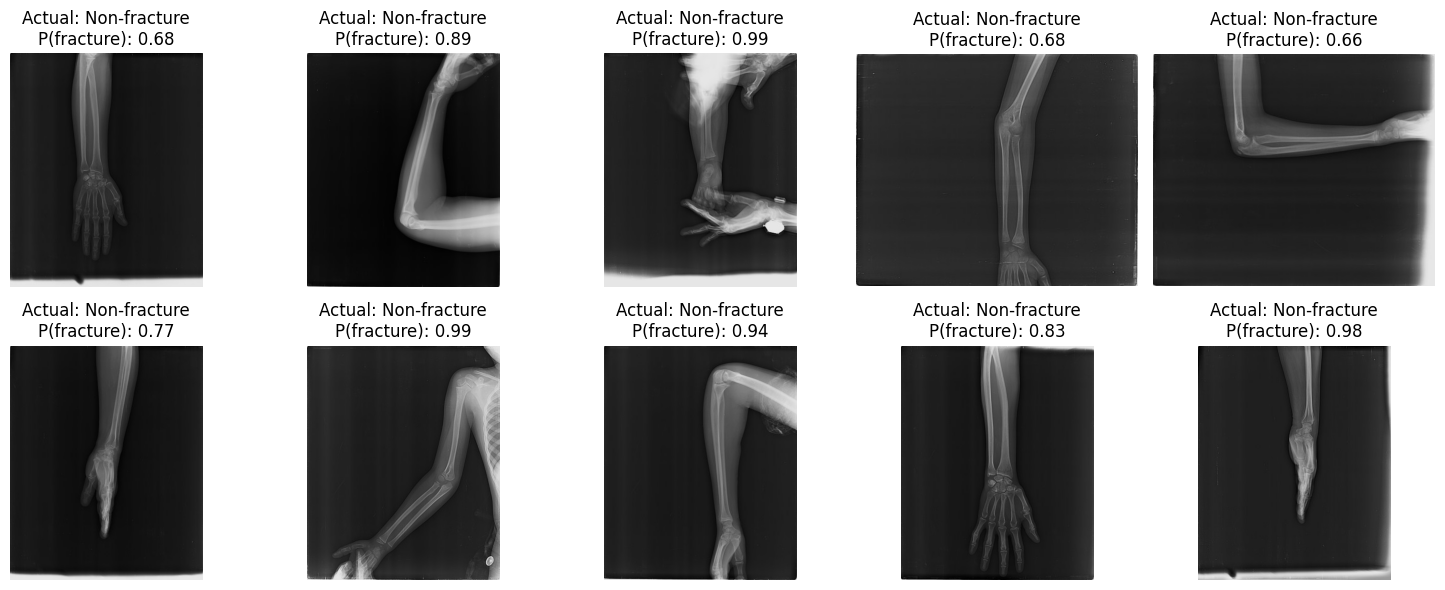

In [128]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, (_, row) in zip(axes.ravel(), fp_df.head(10).iterrows()):
    img = Image.open(row["image"]).convert("RGB")

    ax.imshow(img)
    ax.set_title(
        f"Actual: Non-fracture\nP(fracture): {row['probability']:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

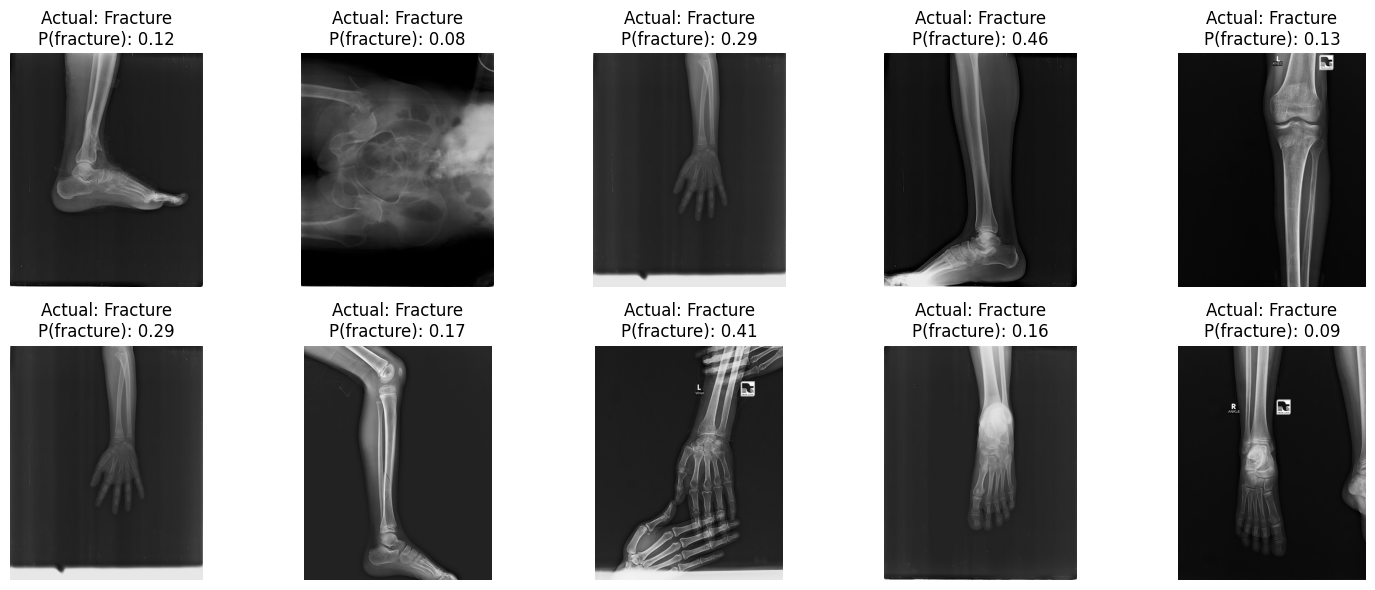

In [129]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, (_, row) in zip(axes.ravel(), fn_df.head(10).iterrows()):
    img = Image.open(row["image"]).convert("RGB")

    ax.imshow(img)
    ax.set_title(
        f"Actual: Fracture\nP(fracture): {row['probability']:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
EXPERIMENT 6

In [130]:
import torch
import timm
import numpy as np
from PIL import Image
from torchvision import transforms
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=False,
    num_classes=2
)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Final yr/best_vit_fracture_exp1.pth",
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Model loaded successfully")

Model loaded successfully


In [131]:
from PIL import Image

normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

def get_views(image):

    # Convert to RGB
    image = image.convert("RGB")

    # Full image
    full = image.resize((224, 224))

    # Resize larger so we can take crops
    large = image.resize((256, 256))

    views = []

    # Full image
    views.append(full)

    # Center crop
    views.append(
        large.crop((16, 16, 240, 240))
    )

    # Top crop
    views.append(
        large.crop((16, 0, 240, 224))
    )

    # Bottom crop
    views.append(
        large.crop((16, 32, 240, 256))
    )

    # Left crop
    views.append(
        large.crop((0, 16, 224, 240))
    )

    # Right crop
    views.append(
        large.crop((32, 16, 256, 240))
    )

    transform = transforms.Compose([
        transforms.ToTensor(),
        normalize
    ])

    views = [transform(v) for v in views]

    return torch.stack(views)

In [132]:
def multi_crop_probability(image_path):

    image = Image.open(image_path).convert("RGB")

    views = get_views(image).to(device)

    with torch.no_grad():
        outputs = model(views)

        probabilities = torch.softmax(outputs, dim=1)[:, 1]

    # Average probability from all views
    final_probability = probabilities.mean().item()

    return final_probability

In [133]:
test_image = test_df.iloc[0]["image"]

prob = multi_crop_probability(test_image)

print("Image:", test_image)
print("Multi-crop fracture probability:", prob)

Image: /content/drive/MyDrive/Final yr/FracAtlas/images/Non_fractured/IMG0003677.jpg
Multi-crop fracture probability: 0.6307232975959778


In [136]:
# Check your existing dataframes
print("Train:", len(train_df))
print("Test :", len(test_df))

Train: 2859
Test : 613


In [139]:
import os
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Final yr/FracAtlas"

# Get every image in FracAtlas
all_images = []

for label_name, label in [
    ("Non_fractured", 0),
    ("Fractured", 1)
]:
    folder = os.path.join(BASE_DIR, "images", label_name)

    for file in os.listdir(folder):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            all_images.append({
                "image": os.path.join(folder, file),
                "label": label
            })

all_df = pd.DataFrame(all_images)

print("Total images:", len(all_df))

Total images: 4085


In [140]:
train_paths = set(train_df["image"])
test_paths = set(test_df["image"])

val_df = all_df[
    ~all_df["image"].isin(train_paths) &
    ~all_df["image"].isin(test_paths)
].copy()

val_df = val_df.reset_index(drop=True)

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nValidation labels:")
print(val_df["label"].value_counts())

Train images: 2859
Validation images: 613
Test images: 613

Validation labels:
label
0    505
1    108
Name: count, dtype: int64


In [141]:
val_probs = []
val_actual = []

for _, row in val_df.iterrows():

    prob = multi_crop_probability(row["image"])

    val_probs.append(prob)
    val_actual.append(row["label"])

    if len(val_probs) % 50 == 0:
        print("Processed:", len(val_probs))

val_probs = np.array(val_probs)
val_actual = np.array(val_actual)

print("Validation images:", len(val_probs))

Processed: 50
Processed: 100
Processed: 150
Processed: 200
Processed: 250
Processed: 300
Processed: 350
Processed: 400
Processed: 450
Processed: 500
Processed: 550
Processed: 600
Validation images: 613


In [142]:
print("all_df:", len(all_df))
print("train_df:", len(train_df))
print("test_df:", len(test_df))
print("val_df:", len(val_df))

print("\nDuplicate paths in all_df:")
print(all_df["image"].duplicated().sum())

print("\nOverlap train/test:",
      len(set(train_df["image"]) & set(test_df["image"])))

print("Overlap train/validation:",
      len(set(train_df["image"]) & set(val_df["image"])))

print("Overlap test/validation:",
      len(set(test_df["image"]) & set(val_df["image"])))

print("\nLabel counts:")
print("Train:")
print(train_df["label"].value_counts())

print("\nValidation:")
print(val_df["label"].value_counts())

print("\nTest:")
print(test_df["label"].value_counts())

all_df: 4085
train_df: 2859
test_df: 613
val_df: 613

Duplicate paths in all_df:
0

Overlap train/test: 0
Overlap train/validation: 0
Overlap test/validation: 0

Label counts:
Train:
label
0    2356
1     503
Name: count, dtype: int64

Validation:
label
0    505
1    108
Name: count, dtype: int64

Test:
label
0    505
1    108
Name: count, dtype: int64


In [143]:
val_probs = []
val_actual = []

for _, row in val_df.iterrows():

    prob = multi_crop_probability(row["image"])

    val_probs.append(prob)
    val_actual.append(row["label"])

    if len(val_probs) % 50 == 0:
        print("Processed:", len(val_probs))

val_probs = np.array(val_probs)
val_actual = np.array(val_actual)

print("Validation images:", len(val_probs))

Processed: 50
Processed: 100
Processed: 150
Processed: 200
Processed: 250
Processed: 300
Processed: 350
Processed: 400
Processed: 450
Processed: 500
Processed: 550
Processed: 600
Validation images: 613


In [144]:
best_threshold = 0
best_f1 = 0

for threshold in np.arange(0.20, 0.81, 0.01):

    predictions = (val_probs >= threshold).astype(int)

    f1 = f1_score(
        val_actual,
        predictions,
        zero_division=0
    )

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

print("Best validation threshold:", best_threshold)
print("Best validation F1:", best_f1)

Best validation threshold: 0.47000000000000025
Best validation F1: 0.7149321266968326


In [145]:
test_probs = []
test_actual = []

for _, row in test_df.iterrows():

    prob = multi_crop_probability(row["image"])

    test_probs.append(prob)
    test_actual.append(row["label"])

    if len(test_probs) % 50 == 0:
        print("Processed:", len(test_probs))

test_probs = np.array(test_probs)
test_actual = np.array(test_actual)

print("Test images:", len(test_probs))

Processed: 50
Processed: 100
Processed: 150
Processed: 200
Processed: 250
Processed: 300
Processed: 350
Processed: 400
Processed: 450
Processed: 500
Processed: 550
Processed: 600
Test images: 613


In [146]:
test_predictions = (
    test_probs >= best_threshold
).astype(int)

accuracy = accuracy_score(
    test_actual,
    test_predictions
)

precision = precision_score(
    test_actual,
    test_predictions,
    zero_division=0
)

recall = recall_score(
    test_actual,
    test_predictions,
    zero_division=0
)

f1 = f1_score(
    test_actual,
    test_predictions,
    zero_division=0
)

auc = roc_auc_score(
    test_actual,
    test_probs
)

cm = confusion_matrix(
    test_actual,
    test_predictions
)

print("\n===== MULTI-CROP TEST RESULTS =====")
print("Threshold :", best_threshold)
print("Accuracy  :", accuracy)
print("Precision :", precision)
print("Recall    :", recall)
print("F1 Score  :", f1)
print("ROC-AUC   :", auc)

print("\nConfusion Matrix:")
print(cm)


===== MULTI-CROP TEST RESULTS =====
Threshold : 0.47000000000000025
Accuracy  : 0.8841761827079935
Precision : 0.6608695652173913
Recall    : 0.7037037037037037
F1 Score  : 0.6816143497757847
ROC-AUC   : 0.8872020535386871

Confusion Matrix:
[[466  39]
 [ 32  76]]


In [ ]:
EXPERIMENT 6-Hard

In [148]:
import torch
import torch.nn as nn
import timm
import numpy as np
import pandas as pd

from PIL import Image, ImageFile
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

ImageFile.LOAD_TRUNCATED_IMAGES = True

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [149]:
model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=False,
    num_classes=2
)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Final yr/best_vit_fracture_exp1.pth",
        map_location=device
    )
)

model = model.to(device)

print("ViT-B/16 loaded successfully")

ViT-B/16 loaded successfully


In [150]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [151]:
class FractureDataset(Dataset):

    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        try:
            image = Image.open(
                row["image"]
            ).convert("RGB")

            label = int(row["label"])

            if self.transform:
                image = self.transform(image)

            return image, label

        except Exception as e:

            print(
                f"Problem loading image {idx}: {e}"
            )

            next_idx = (idx + 1) % len(self.df)

            return self.__getitem__(next_idx)

In [152]:
train_dataset = FractureDataset(
    train_df,
    transform=train_transform
)

val_dataset = FractureDataset(
    val_df,
    transform=eval_transform
)

test_dataset = FractureDataset(
    test_df,
    transform=eval_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 2859
Validation: 613
Test: 613


In [153]:
train_eval_dataset = FractureDataset(
    train_df,
    transform=eval_transform
)

train_eval_loader = DataLoader(
    train_eval_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

In [154]:
model.eval()

train_probabilities = []
train_labels = []

with torch.no_grad():

    for images, labels in train_eval_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.softmax(
            outputs,
            dim=1
        )[:, 1]

        train_probabilities.extend(
            probs.cpu().numpy()
        )

        train_labels.extend(
            labels.numpy()
        )

train_probabilities = np.array(
    train_probabilities
)

train_labels = np.array(
    train_labels
)

print(
    "Training predictions:",
    len(train_probabilities)
)

Training predictions: 2859


In [155]:
# Probability of the correct class
correct_class_probability = np.where(
    train_labels == 1,
    train_probabilities,
    1 - train_probabilities
)

# Difficulty:
# low probability for the correct class = difficult image
difficulty = 1 - correct_class_probability

# Add a small baseline so every image can still be sampled
sample_weights = 0.25 + difficulty

print("Minimum weight:", sample_weights.min())
print("Maximum weight:", sample_weights.max())

Minimum weight: 0.25008297
Maximum weight: 1.2412264


In [156]:
sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(train_dataset),
    replacement=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    sampler=sampler,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Dataloaders ready")

Dataloaders ready


In [157]:
criterion = nn.CrossEntropyLoss()

In [158]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-5,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=8
)

In [159]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    return (
        running_loss / total,
        correct / total
    )

In [160]:
def evaluate(model, loader):

    model.eval()

    probabilities = []
    actual = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            probs = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            probabilities.extend(
                probs.cpu().numpy()
            )

            actual.extend(
                labels.numpy()
            )

    probabilities = np.array(probabilities)
    actual = np.array(actual)

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    acc = accuracy_score(
        actual,
        predictions
    )

    precision = precision_score(
        actual,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        actual,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        actual,
        predictions,
        zero_division=0
    )

    auc = roc_auc_score(
        actual,
        probabilities
    )

    return acc, precision, recall, f1, auc, probabilities, actual

In [161]:
best_f1 = 0

save_path = (
    "/content/drive/MyDrive/Final yr/"
    "best_vit_fracture_exp6.pth"
)

for epoch in range(8):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    (
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        val_auc,
        _,
        _
    ) = evaluate(
        model,
        val_loader
    )

    scheduler.step()

    print(
        f"\nEpoch {epoch + 1}/8"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Train Acc : {train_acc:.4f}"
    )

    print(
        f"Val Acc   : {val_acc:.4f}"
    )

    print(
        f"Val Prec  : {val_precision:.4f}"
    )

    print(
        f"Val Recall: {val_recall:.4f}"
    )

    print(
        f"Val F1    : {val_f1:.4f}"
    )

    print(
        f"Val AUC   : {val_auc:.4f}"
    )

    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            model.state_dict(),
            save_path
        )

        print("Best model saved!")


Epoch 1/8
Train Loss: 0.2017
Train Acc : 0.9363
Val Acc   : 0.8874
Val Prec  : 0.7349
Val Recall: 0.5648
Val F1    : 0.6387
Val AUC   : 0.8423
Best model saved!

Epoch 2/8
Train Loss: 0.1791
Train Acc : 0.9433
Val Acc   : 0.8809
Val Prec  : 0.7059
Val Recall: 0.5556
Val F1    : 0.6218
Val AUC   : 0.8469

Epoch 3/8
Train Loss: 0.1483
Train Acc : 0.9524
Val Acc   : 0.8923
Val Prec  : 0.7763
Val Recall: 0.5463
Val F1    : 0.6413
Val AUC   : 0.8764
Best model saved!

Epoch 4/8
Train Loss: 0.0931
Train Acc : 0.9776
Val Acc   : 0.8891
Val Prec  : 0.7381
Val Recall: 0.5741
Val F1    : 0.6458
Val AUC   : 0.8843
Best model saved!

Epoch 5/8
Train Loss: 0.0562
Train Acc : 0.9825
Val Acc   : 0.8940
Val Prec  : 0.7471
Val Recall: 0.6019
Val F1    : 0.6667
Val AUC   : 0.8653
Best model saved!

Epoch 6/8
Train Loss: 0.0470
Train Acc : 0.9885
Val Acc   : 0.9021
Val Prec  : 0.7857
Val Recall: 0.6111
Val F1    : 0.6875
Val AUC   : 0.8738
Best model saved!

Epoch 7/8
Train Loss: 0.0227
Train Acc : 0.99

In [162]:
model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Final yr/"
        "best_vit_fracture_exp6.pth",
        map_location=device
    )
)

model.eval()

print("Best Experiment 6 model loaded")

Best Experiment 6 model loaded


In [163]:
(
    val_acc,
    val_precision,
    val_recall,
    val_f1,
    val_auc,
    val_probs,
    val_actual
) = evaluate(
    model,
    val_loader
)

best_threshold = 0.5
best_val_f1 = 0

for threshold in np.arange(
    0.20,
    0.81,
    0.01
):

    predictions = (
        val_probs >= threshold
    ).astype(int)

    f1 = f1_score(
        val_actual,
        predictions,
        zero_division=0
    )

    if f1 > best_val_f1:

        best_val_f1 = f1
        best_threshold = threshold

print(
    "Best validation threshold:",
    best_threshold
)

print(
    "Best validation F1:",
    best_val_f1
)

Best validation threshold: 0.4400000000000002
Best validation F1: 0.694300518134715


In [164]:
(
    _,
    _,
    _,
    _,
    _,
    test_probs,
    test_actual
) = evaluate(
    model,
    test_loader
)

test_predictions = (
    test_probs >= best_threshold
).astype(int)

accuracy = accuracy_score(
    test_actual,
    test_predictions
)

precision = precision_score(
    test_actual,
    test_predictions,
    zero_division=0
)

recall = recall_score(
    test_actual,
    test_predictions,
    zero_division=0
)

f1 = f1_score(
    test_actual,
    test_predictions,
    zero_division=0
)

auc = roc_auc_score(
    test_actual,
    test_probs
)

cm = confusion_matrix(
    test_actual,
    test_predictions
)

print("\n==============================")
print("EXPERIMENT 6 TEST RESULTS")
print("==============================")

print(
    "Threshold :", best_threshold
)

print(
    "Accuracy  :", accuracy
)

print(
    "Precision :", precision
)

print(
    "Recall    :", recall
)

print(
    "F1 Score  :", f1
)

print(
    "ROC-AUC   :", auc
)

print("\nConfusion Matrix:")
print(cm)


EXPERIMENT 6 TEST RESULTS
Threshold : 0.4400000000000002
Accuracy  : 0.8858075040783034
Precision : 0.7159090909090909
Recall    : 0.5833333333333334
F1 Score  : 0.6428571428571429
ROC-AUC   : 0.8572423909057573

Confusion Matrix:
[[480  25]
 [ 45  63]]


In [ ]:
CNN + ViT

In [165]:
!pip install -q timm

In [166]:
import os
import numpy as np
import pandas as pd
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

import timm

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

In [167]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [168]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [169]:
class FractureDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        path = row["image"]
        label = int(row["label"])

        try:
            image = Image.open(path).convert("RGB")

        except Exception as e:
            print("Problem with:", path)
            print(e)

            # Try another image instead
            new_idx = (idx + 1) % len(self.df)
            return self.__getitem__(new_idx)

        if self.transform:
            image = self.transform(image)

        return image, label

In [170]:
train_dataset = FractureDataset(
    train_df,
    train_transform
)

val_dataset = FractureDataset(
    val_df,
    test_transform
)

test_dataset = FractureDataset(
    test_df,
    test_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 2859
Validation: 613
Test: 613


In [171]:
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [172]:
classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:", class_weights)

Class weights: tensor([0.6067, 2.8419], device='cuda:0')


In [173]:
class CNNViTHybrid(nn.Module):

    def __init__(self):

        super().__init__()

        # -------------------------
        # CNN: ResNet18
        # -------------------------

        self.cnn = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT
        )

        # Remove original classification layer
        self.cnn.fc = nn.Identity()

        # ResNet18 feature size = 512
        self.cnn_features = 512


        # -------------------------
        # ViT-B/16
        # -------------------------

        self.vit = timm.create_model(
            "vit_base_patch16_224",
            pretrained=True,
            num_classes=0
        )

        # ViT-B/16 feature size = 768
        self.vit_features = 768


        # -------------------------
        # Feature Fusion
        # -------------------------

        self.fusion = nn.Sequential(

            nn.LayerNorm(
                self.cnn_features + self.vit_features
            ),

            nn.Linear(
                self.cnn_features + self.vit_features,
                512
            ),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(
                512,
                2
            )
        )


    def forward(self, x):

        # CNN local features
        cnn_features = self.cnn(x)

        # ViT global features
        vit_features = self.vit(x)

        # Combine features
        combined = torch.cat(
            [cnn_features, vit_features],
            dim=1
        )

        # Classification
        output = self.fusion(combined)

        return output

In [174]:
model = CNNViTHybrid().to(device)

print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 61.2MB/s]


CNNViTHybrid(
  (cnn): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_ru

In [175]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

In [176]:
optimizer = optim.AdamW(
    [
        {
            "params": model.cnn.parameters(),
            "lr": 1e-5
        },

        {
            "params": model.vit.parameters(),
            "lr": 1e-5
        },

        {
            "params": model.fusion.parameters(),
            "lr": 1e-4
        }
    ],

    weight_decay=1e-4
)

In [177]:
EPOCHS = 10

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

In [178]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item()

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    loss = running_loss / len(loader)

    accuracy = correct / total

    return loss, accuracy

In [179]:
def evaluate(model, loader):

    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            all_probs.extend(
                probabilities.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)

    predictions = (
        all_probs >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        all_labels,
        predictions
    )

    precision = precision_score(
        all_labels,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        predictions,
        zero_division=0
    )

    auc = roc_auc_score(
        all_labels,
        all_probs
    )

    return accuracy, precision, recall, f1, auc

In [ ]:
best_f1 = 0

save_path = (
    "/content/drive/MyDrive/Final yr/"
    "best_cnn_vit_hybrid.pth"
)

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_acc, val_precision, val_recall, val_f1, val_auc = evaluate(
        model,
        val_loader
    )

    scheduler.step()

    print(
        f"Epoch {epoch+1}/{EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Train Accuracy: {train_acc:.4f}"
    )

    print(
        f"Val Accuracy: {val_acc:.4f}"
    )

    print(
        f"Val Precision: {val_precision:.4f}"
    )

    print(
        f"Val Recall: {val_recall:.4f}"
    )

    print(
        f"Val F1: {val_f1:.4f}"
    )

    print(
        f"Val AUC: {val_auc:.4f}"
    )

    print("-" * 50)


    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            model.state_dict(),
            save_path
        )

        print("Best model saved!")

Epoch 1/10
Train Loss: 0.6624
Train Accuracy: 0.7660
Val Accuracy: 0.8564
Val Precision: 0.6190
Val Recall: 0.4815
Val F1: 0.5417
Val AUC: 0.8545
--------------------------------------------------
Best model saved!
Epoch 2/10
Train Loss: 0.5630
Train Accuracy: 0.8538
Val Accuracy: 0.8874
Val Precision: 0.9535
Val Recall: 0.3796
Val F1: 0.5430
Val AUC: 0.8320
--------------------------------------------------
Best model saved!
Epoch 3/10
Train Loss: 0.5402
Train Accuracy: 0.8849
Val Accuracy: 0.8891
Val Precision: 0.8846
Val Recall: 0.4259
Val F1: 0.5750
Val AUC: 0.8143
--------------------------------------------------
Best model saved!
Epoch 4/10
Train Loss: 0.4946
Train Accuracy: 0.9070
Val Accuracy: 0.8777
Val Precision: 0.6542
Val Recall: 0.6481
Val F1: 0.6512
Val AUC: 0.8855
--------------------------------------------------
Best model saved!
Epoch 5/10
Train Loss: 0.4380
Train Accuracy: 0.9255
Val Accuracy: 0.9021
Val Precision: 0.8871
Val Recall: 0.5093
Val F1: 0.6471
Val AUC: 0

In [ ]:
gpu loat cpu----

In [2]:
import torch
import torch.nn as nn
from torchvision import models
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [3]:
class CNNViTHybrid(nn.Module):

    def __init__(self):
        super().__init__()

        # CNN branch
        self.cnn = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT
        )

        self.cnn.fc = nn.Identity()

        # ViT branch
        self.vit = timm.create_model(
            "vit_base_patch16_224",
            pretrained=True,
            num_classes=0
        )

        # Feature fusion
        self.fusion = nn.Sequential(

            nn.LayerNorm(512 + 768),

            nn.Linear(512 + 768, 512),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(512, 2)
        )

    def forward(self, x):

        cnn_features = self.cnn(x)

        vit_features = self.vit(x)

        combined = torch.cat(
            [cnn_features, vit_features],
            dim=1
        )

        output = self.fusion(combined)

        return output

In [4]:
model = CNNViTHybrid().to(device)

print("Model created")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 92.4MB/s]


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Model created


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
save_path = "/content/drive/MyDrive/Final yr/best_cnn_vit_hybrid.pth"

model.load_state_dict(
    torch.load(
        save_path,
        map_location=device
    )
)

model.to(device)

print("Best CNN + ViT model loaded successfully!")

Best CNN + ViT model loaded successfully!


In [12]:
print("train_df exists:", "train_df" in globals())
print("val_df exists:", "val_df" in globals())
print("test_df exists:", "test_df" in globals())

train_df exists: False
val_df exists: False
test_df exists: False


In [14]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

BASE_DIR = "/content/drive/MyDrive/Final yr/FracAtlas"

fractured_dir = os.path.join(
    BASE_DIR, "images", "Fractured"
)

nonfractured_dir = os.path.join(
    BASE_DIR, "images", "Non_fractured"
)

data = []

# Fractured = 1
for file in os.listdir(fractured_dir):
    path = os.path.join(fractured_dir, file)

    if os.path.isfile(path):
        data.append([path, 1])

# Non-fractured = 0
for file in os.listdir(nonfractured_dir):
    path = os.path.join(nonfractured_dir, file)

    if os.path.isfile(path):
        data.append([path, 0])

all_df = pd.DataFrame(
    data,
    columns=["image", "label"]
)

print("Total images:", len(all_df))
print(all_df["label"].value_counts())

Total images: 4085
label
0    3366
1     719
Name: count, dtype: int64


In [15]:
train_df, temp_df = train_test_split(
    all_df,
    test_size=0.30,
    stratify=all_df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTrain:")
print(train_df["label"].value_counts())

print("\nValidation:")
print(val_df["label"].value_counts())

print("\nTest:")
print(test_df["label"].value_counts())

Train: 2859
Validation: 613
Test: 613

Train:
label
0    2356
1     503
Name: count, dtype: int64

Validation:
label
0    505
1    108
Name: count, dtype: int64

Test:
label
0    505
1    108
Name: count, dtype: int64


In [16]:
from PIL import Image, ImageFile
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

ImageFile.LOAD_TRUNCATED_IMAGES = True

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class FractureDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        try:
            image = Image.open(row["image"]).convert("RGB")
        except Exception:
            return self.__getitem__((idx + 1) % len(self.df))

        if self.transform:
            image = self.transform(image)

        return image, int(row["label"])


test_dataset = FractureDataset(
    test_df,
    test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))

Test images: 613
Test batches: 77


In [17]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

model.eval()

all_labels = []
all_probs = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.softmax(
            outputs,
            dim=1
        )[:, 1]

        all_probs.extend(
            probs.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

predictions = (all_probs >= 0.5).astype(int)

accuracy = accuracy_score(all_labels, predictions)
precision = precision_score(all_labels, predictions, zero_division=0)
recall = recall_score(all_labels, predictions, zero_division=0)
f1 = f1_score(all_labels, predictions, zero_division=0)
auc = roc_auc_score(all_labels, all_probs)

cm = confusion_matrix(
    all_labels,
    predictions
)

print("\nCNN + ViT TEST RESULTS")
print("======================")
print(f"Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall    : {recall:.4f} ({recall*100:.2f}%)")
print(f"F1 Score  : {f1:.4f} ({f1*100:.2f}%)")
print(f"ROC-AUC   : {auc:.4f} ({auc*100:.2f}%)")

print("\nConfusion Matrix:")
print(cm)


CNN + ViT TEST RESULTS
Accuracy  : 0.8972 (89.72%)
Precision : 0.7711 (77.11%)
Recall    : 0.5926 (59.26%)
F1 Score  : 0.6702 (67.02%)
ROC-AUC   : 0.8512 (85.12%)

Confusion Matrix:
[[486  19]
 [ 44  64]]


In [ ]:
model.load_state_dict(
    torch.load(
        save_path,
        map_location=device
    )
)

model.to(device)

print("Best CNN + ViT model loaded.")

In [ ]:
test_acc, test_precision, test_recall, test_f1, test_auc = evaluate(
    model,
    test_loader
)

print("\nFINAL TEST RESULTS")
print("-------------------------")

print(
    f"Accuracy  : {test_acc:.4f}"
)

print(
    f"Precision : {test_precision:.4f}"
)

print(
    f"Recall    : {test_recall:.4f}"
)

print(
    f"F1 Score  : {test_f1:.4f}"
)

print(
    f"ROC-AUC   : {test_auc:.4f}"
)

In [ ]:
def get_predictions(model, loader):

    model.eval()

    labels_all = []
    probs_all = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            probs = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            probs_all.extend(
                probs.cpu().numpy()
            )

            labels_all.extend(
                labels.numpy()
            )

    return (
        np.array(labels_all),
        np.array(probs_all)
    )


test_labels, test_probs = get_predictions(
    model,
    test_loader
)

test_predictions = (
    test_probs >= 0.5
).astype(int)

cm = confusion_matrix(
    test_labels,
    test_predictions
)

print("Confusion Matrix:")
print(cm)